In [1]:
!pip install -q python-chess pandas numpy matplotlib seaborn
!apt-get -qq update
!apt-get -qq install -y stockfish

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package stockfish.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../stockfish_16-1build1_amd64.deb ...
Unpacking stockfish (16-1build1) ...
Setting up stockfish (16-1build1) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [2]:
import chess
import chess.pgn
import chess.engine

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import io
import os
import shutil

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
stockfish_path = shutil.which("stockfish")

if stockfish_path is None:
    possible_paths = [
        "/usr/games/stockfish",
        "/usr/bin/stockfish"
    ]

    for path in possible_paths:
        if os.path.exists(path):
            stockfish_path = path
            break

print("Stockfish path:", stockfish_path)

if stockfish_path is None:
    raise FileNotFoundError("Stockfish installation not found.")

engine = chess.engine.SimpleEngine.popen_uci(stockfish_path)

print("Stockfish engine connected successfully!")

Stockfish path: /usr/games/stockfish
Stockfish engine connected successfully!


In [4]:
sample_pgn = """
[Event "Chess Review Test"]
[White "Player 1"]
[Black "Player 2"]
[Result "*"]

1. e4 e5
2. Nf3 Nc6
3. Bc4 Bc5
4. c3 Nf6
5. d3 d6
6. O-O O-O
7. Re1 a6
8. h3 Ba7
9. Nbd2 h6
10. Nf1 Be6
11. Bb3 Bxb3
12. axb3 d5
13. exd5 Qxd5
14. Ne3 Qd7 *
"""

game = chess.pgn.read_game(io.StringIO(sample_pgn))

print("White:", game.headers["White"])
print("Black:", game.headers["Black"])
print("Result:", game.headers["Result"])
print("Game loaded successfully!")

White: Player 1
Black: Player 2
Result: *
Game loaded successfully!


In [5]:
board = game.board()

print(board)

print("\nMoves:")

for move in game.mainline_moves():
    print(board.san(move), end=" ")
    board.push(move)

r n b q k b n r
p p p p p p p p
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
P P P P P P P P
R N B Q K B N R

Moves:
e4 e5 Nf3 Nc6 Bc4 Bc5 c3 Nf6 d3 d6 O-O O-O Re1 a6 h3 Ba7 Nbd2 h6 Nf1 Be6 Bb3 Bxb3 axb3 d5 exd5 Qxd5 Ne3 Qd7 

In [6]:
board = game.board()

analysis_data = []

for move in game.mainline_moves():

    mover = board.turn

    # Analyse the position before the move
    before = engine.analyse(
        board,
        chess.engine.Limit(depth=12)
    )

    best_move = before["pv"][0]
    best_move_san = board.san(best_move)

    eval_before = before["score"].pov(mover).score(
        mate_score=10000
    )

    played_move_san = board.san(move)

    # Play the actual move
    board.push(move)

    # Analyse the resulting position
    after = engine.analyse(
        board,
        chess.engine.Limit(depth=12)
    )

    eval_after = after["score"].pov(mover).score(
        mate_score=10000
    )

    # Calculate evaluation loss
    loss = max(0, eval_before - eval_after)

    if move == best_move:
        quality = "Best"
    elif loss < 50:
        quality = "Good"
    elif loss < 100:
        quality = "Inaccuracy"
    elif loss < 200:
        quality = "Mistake"
    else:
        quality = "Blunder"

    analysis_data.append({
        "move_number": board.fullmove_number - (1 if mover == chess.BLACK else 0),
        "player": "White" if mover == chess.WHITE else "Black",
        "played_move": played_move_san,
        "best_move": best_move_san,
        "eval_before": eval_before,
        "eval_after": eval_after,
        "centipawn_loss": loss,
        "classification": quality
    })

print("Game analysis completed!")

Game analysis completed!


In [7]:
df = pd.DataFrame(analysis_data)

display(df)

,move_number,player,played_move,best_move,eval_before,eval_after,centipawn_loss,classification
0,1,White,e4,e4,40,36,4,Best
1,1,Black,e5,e5,-41,-36,0,Best
2,2,White,Nf3,Nf3,35,27,8,Best
3,2,Black,Nc6,Nc6,-1,-38,37,Best
4,3,White,Bc4,Bb5,27,22,5,Good
5,3,Black,Bc5,Nf6,-22,-45,23,Good
6,4,White,c3,c3,17,3,14,Best
7,4,Black,Nf6,Nf6,-2,-23,21,Best
8,5,White,d3,d3,35,27,8,Best
9,5,Black,d6,d6,-16,-16,0,Best


In [8]:
print("Total moves analysed:", len(df))

print("\nMove quality distribution:")

print(df["classification"].value_counts())

Total moves analysed: 28

Move quality distribution:
classification
Good          15
Best          12
Inaccuracy     1
Name: count, dtype: int64


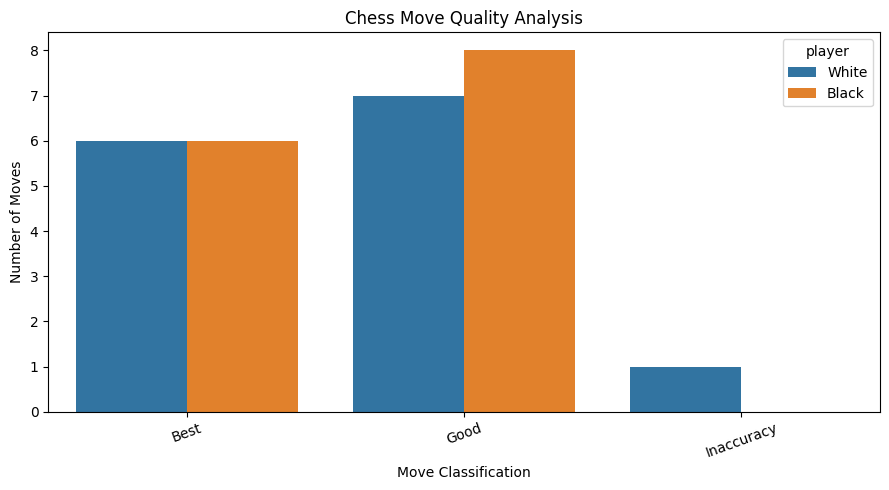

In [9]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="classification",
    hue="player"
)

plt.title("Chess Move Quality Analysis")
plt.xlabel("Move Classification")
plt.ylabel("Number of Moves")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [10]:
df.to_csv(
    "chess_review_report.csv",
    index=False
)

print("Chess review report saved!")

Chess review report saved!


In [11]:
engine.quit()

print("Stockfish engine closed.")

Stockfish engine closed.


In [12]:
sample_pgn = """
[Event "Chess Review Test"]
[White "Player 1"]
[Black "Player 2"]
[Result "*"]

1. e4 e5
2. Nf3 Nc6
3. Bc4 Bc5
4. c3 Nf6
5. d3 d6
6. O-O O-O
7. Re1 a6
8. h3 Ba7
9. Nbd2 h6
10. Nf1 Be6
11. Bb3 Bxb3
12. axb3 d5
13. exd5 Qxd5
14. Ne3 Qd7 *
"""

import io

game = chess.pgn.read_game(io.StringIO(sample_pgn))

print("White:", game.headers["White"])
print("Black:", game.headers["Black"])
print("Result:", game.headers["Result"])
print("Game loaded successfully!")

White: Player 1
Black: Player 2
Result: *
Game loaded successfully!


In [13]:
board = game.board()

print(board)

print("\nMoves played:")

for move in game.mainline_moves():
    print(board.san(move), end=" ")
    board.push(move)

r n b q k b n r
p p p p p p p p
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
P P P P P P P P
R N B Q K B N R

Moves played:
e4 e5 Nf3 Nc6 Bc4 Bc5 c3 Nf6 d3 d6 O-O O-O Re1 a6 h3 Ba7 Nbd2 h6 Nf1 Be6 Bb3 Bxb3 axb3 d5 exd5 Qxd5 Ne3 Qd7 

In [15]:
board = game.board()

analysis_data = []

for move in game.mainline_moves():

    # Identify whose move it is
    mover = board.turn
    player = "White" if mover == chess.WHITE else "Black"

    # 1. Analyse the position before the move
    before = engine.analyse(
        board,
        chess.engine.Limit(depth=12)
    )

    # Stockfish's recommended move
    best_move = before["pv"][0]
    best_move_san = board.san(best_move)

    # Evaluation from the current player's perspective
    eval_before = before["score"].pov(mover).score(
        mate_score=10000
    )

    # 2. Record the actual move played
    played_move_san = board.san(move)

    # 3. Play the actual move
    board.push(move)

    # 4. Analyse the resulting position
    after = engine.analyse(
        board,
        chess.engine.Limit(depth=12)
    )

    eval_after = after["score"].pov(mover).score(
        mate_score=10000
    )

    # 5. Calculate evaluation loss
    centipawn_loss = max(0, eval_before - eval_after)

    # 6. Classify move quality
    if move == best_move:
        quality = "Best"
    elif centipawn_loss < 50:
        quality = "Good"
    elif centipawn_loss < 100:
        quality = "Inaccuracy"
    elif centipawn_loss < 200:
        quality = "Mistake"
    else:
        quality = "Blunder"

    # 7. Store the result
    analysis_data.append({
        "move_number": board.fullmove_number -
                       (1 if mover == chess.BLACK else 0),
        "player": player,
        "played_move": played_move_san,
        "best_move": best_move_san,
        "eval_before": eval_before,
        "eval_after": eval_after,
        "centipawn_loss": centipawn_loss,
        "classification": quality
    })

print("Game analysis completed!")
print("Total moves analysed:", len(analysis_data))

Re-connecting to Stockfish engine...
Game analysis completed!
Total moves analysed: 28


In [16]:
df = pd.DataFrame(analysis_data)

display(df)

,move_number,player,played_move,best_move,eval_before,eval_after,centipawn_loss,classification
0,1,White,e4,e4,40,36,4,Best
1,1,Black,e5,e5,-41,-36,0,Best
2,2,White,Nf3,Nf3,35,27,8,Best
3,2,Black,Nc6,Nc6,-1,-38,37,Best
4,3,White,Bc4,Bb5,27,22,5,Good
5,3,Black,Bc5,Nf6,-22,-45,23,Good
6,4,White,c3,c3,17,3,14,Best
7,4,Black,Nf6,Nf6,-2,-23,21,Best
8,5,White,d3,d3,35,27,8,Best
9,5,Black,d6,d6,-16,-16,0,Best


In [17]:
print("Dataset shape:", df.shape)

print("\nFirst 5 records:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (28, 8)

First 5 records:


,move_number,player,played_move,best_move,eval_before,eval_after,centipawn_loss,classification
0,1,White,e4,e4,40,36,4,Best
1,1,Black,e5,e5,-41,-36,0,Best
2,2,White,Nf3,Nf3,35,27,8,Best
3,2,Black,Nc6,Nc6,-1,-38,37,Best
4,3,White,Bc4,Bb5,27,22,5,Good



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   move_number     28 non-null     int64 
 1   player          28 non-null     object
 2   played_move     28 non-null     object
 3   best_move       28 non-null     object
 4   eval_before     28 non-null     int64 
 5   eval_after      28 non-null     int64 
 6   centipawn_loss  28 non-null     int64 
 7   classification  28 non-null     object
dtypes: int64(4), object(4)
memory usage: 1.9+ KB


In [18]:
# Count move classifications for each player

performance = pd.crosstab(
    df["player"],
    df["classification"]
)

display(performance)

classification,Best,Good,Inaccuracy
player,,,
Black,6,8,0
White,6,7,1


In [19]:
mistake_categories = ["Inaccuracy", "Mistake", "Blunder"]

for player in ["White", "Black"]:
    total_mistakes = df[
        (df["player"] == player) &
        (df["classification"].isin(mistake_categories))
    ].shape[0]

    print(player, "mistakes:", total_mistakes)

White mistakes: 1
Black mistakes: 0


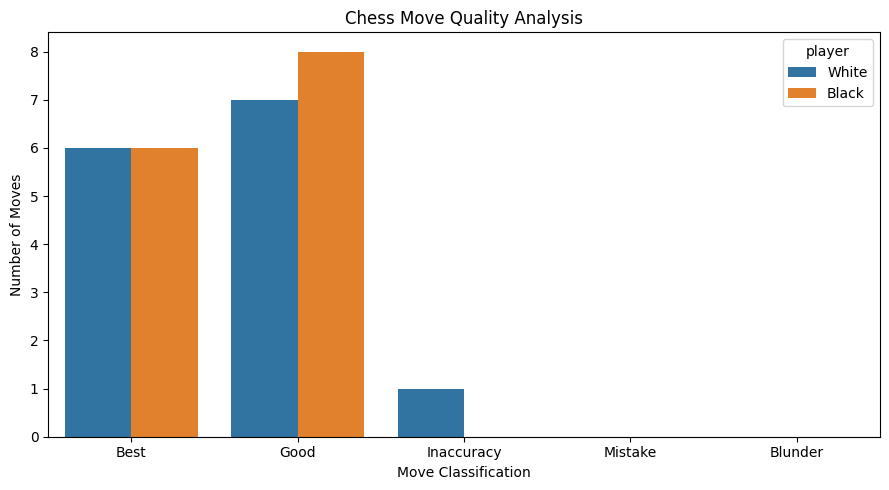

In [20]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="classification",
    hue="player",
    order=["Best", "Good", "Inaccuracy", "Mistake", "Blunder"]
)

plt.title("Chess Move Quality Analysis")
plt.xlabel("Move Classification")
plt.ylabel("Number of Moves")
plt.tight_layout()
plt.show()

In [21]:
df.to_csv("chess_review_report.csv", index=False)

print("CSV exported successfully!")

CSV exported successfully!


In [22]:
from google.colab import files

files.download("chess_review_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import requests

username = "KHHOMAL"

url = f"https://lichess.org/api/games/user/{username}"

params = {
    "max": 20,
    "opening": "false",
    "clocks": "false",
    "evals": "false"
}

headers = {
    "Accept": "application/x-chess-pgn",
    "User-Agent": "ChessReviewBot/1.0"
}

response = requests.get(
    url,
    params=params,
    headers=headers
)

print("Status:", response.status_code)
print("Downloaded bytes:", len(response.content))

if response.status_code == 200 and len(response.content) > 0:
    with open("lichess_games.pgn", "wb") as f:
        f.write(response.content)

    print("PGN downloaded successfully!")
else:
    print(response.text[:500])

Status: 404
Downloaded bytes: 11865
<!DOCTYPE html><html lang="en-GB" class="" style="---ui-roundness:8px;---bg-opacity:50;"><!-- Lichess is open source! See https://lichess.org/source --><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1, minimum-scale=1, viewport-fit=cover"><meta http-equiv="Content-Security-Policy" content="default-src 'self'; connect-src 'self' blob: data: ws://*.lichess.org https://explorer.lichess.org https://tablebase.lichess.org; style-src 'self' 'unsafe-inline';


In [25]:
pgn_filename = "lichess_games.pgn"

In [26]:
import requests

url = "https://lichess.org/api/user/KHHOMAL"

response = requests.get(
    url,
    headers={"User-Agent": "ChessReviewBot/1.0"}
)

print("Status:", response.status_code)

if response.status_code == 200:
    print("Lichess account verified!")
    print(response.json()["username"])
else:
    print(response.text[:300])

Status: 200
Lichess account verified!
KHHOMAL


In [27]:
import requests

url = "https://lichess.org/api/games/user/KHHOMAL"

response = requests.get(
    url,
    params={"max": 5},
    headers={
        "Accept": "application/x-chess-pgn",
        "User-Agent": "ChessReviewBot/1.0 (student project)"
    }
)

print("Status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))
print("Downloaded bytes:", len(response.content))

if response.status_code == 200 and len(response.content) > 0:
    with open("/content/lichess_games.pgn", "wb") as f:
        f.write(response.content)
    print("PGN saved successfully!")
else:
    print("Game export endpoint is not working.")

Status: 404
Content type: text/html; charset=utf-8
Downloaded bytes: 11865
Game export endpoint is not working.


In [28]:
from google.colab import files

uploaded = files.upload()

pgn_filename = next(iter(uploaded))

print("Uploaded file:", pgn_filename)
print("File size:", len(uploaded[pgn_filename]), "bytes")

Saving chess_com_games_2026-11-15.pgn to chess_com_games_2026-11-15.pgn
Uploaded file: chess_com_games_2026-11-15.pgn
File size: 31882 bytes


In [29]:
import chess.pgn

games = []

with open(pgn_filename, "r", encoding="utf-8-sig") as pgn_file:

    while True:
        game = chess.pgn.read_game(pgn_file)

        if game is None:
            break

        games.append(game)

print("Total games loaded:", len(games))

Total games loaded: 50


In [30]:
for i, game in enumerate(games[:5], start=1):
    print(f"\nGame {i}")
    print("White:", game.headers.get("White"))
    print("Black:", game.headers.get("Black"))
    print("Result:", game.headers.get("Result"))


Game 1
White: SocialFist
Black: Kensei_17
Result: 0-1

Game 2
White: Kensei_17
Black: isandomirsky
Result: 0-1

Game 3
White: AmbujNeo
Black: Kensei_17
Result: 1-0

Game 4
White: Male_Ants
Black: Kensei_17
Result: 0-1

Game 5
White: Kensei_17
Black: SL_CHESS_MORA
Result: 0-1


In [32]:
engine = connect_stockfish()

Stockfish connected successfully!


In [33]:
analysis_data = []

for game_index, game in enumerate(games, start=1):

    board = game.board()

    white = game.headers.get("White", "Unknown")
    black = game.headers.get("Black", "Unknown")
    result = game.headers.get("Result", "*")

    print(f"Analysing game {game_index}/{len(games)}")

    for move in game.mainline_moves():

        mover = board.turn
        player = "White" if mover == chess.WHITE else "Black"
        move_number = board.fullmove_number

        # Analyse position before the move
        before = engine.analyse(
            board,
            chess.engine.Limit(depth=12)
        )

        best_move = before["pv"][0]
        best_move_san = board.san(best_move)

        eval_before = before["score"].pov(mover).score(
            mate_score=10000
        )

        played_move = board.san(move)

        # Play actual move
        board.push(move)

        # Analyse position after the move
        after = engine.analyse(
            board,
            chess.engine.Limit(depth=12)
        )

        eval_after = after["score"].pov(mover).score(
            mate_score=10000
        )

        loss = max(0, eval_before - eval_after)

        if move == best_move:
            quality = "Best"
        elif loss < 50:
            quality = "Good"
        elif loss < 100:
            quality = "Inaccuracy"
        elif loss < 200:
            quality = "Mistake"
        else:
            quality = "Blunder"

        analysis_data.append({
            "game_id": game_index,
            "white": white,
            "black": black,
            "result": result,
            "move_number": move_number,
            "player": player,
            "played_move": played_move,
            "best_move": best_move_san,
            "eval_before": eval_before,
            "eval_after": eval_after,
            "centipawn_loss": loss,
            "classification": quality
        })

print("\nAnalysis completed!")
print("Total games:", len(games))
print("Total moves:", len(analysis_data))

Analysing game 1/50
Analysing game 2/50
Analysing game 3/50
Analysing game 4/50
Analysing game 5/50
Analysing game 6/50
Analysing game 7/50
Analysing game 8/50
Analysing game 9/50
Analysing game 10/50
Analysing game 11/50
Analysing game 12/50
Analysing game 13/50
Analysing game 14/50
Analysing game 15/50
Analysing game 16/50
Analysing game 17/50
Analysing game 18/50
Analysing game 19/50
Analysing game 20/50
Analysing game 21/50
Analysing game 22/50
Analysing game 23/50
Analysing game 24/50
Analysing game 25/50
Analysing game 26/50
Analysing game 27/50
Analysing game 28/50
Analysing game 29/50
Analysing game 30/50
Analysing game 31/50
Analysing game 32/50
Analysing game 33/50
Analysing game 34/50
Analysing game 35/50
Analysing game 36/50
Analysing game 37/50
Analysing game 38/50
Analysing game 39/50
Analysing game 40/50
Analysing game 41/50
Analysing game 42/50
Analysing game 43/50
Analysing game 44/50
Analysing game 45/50
Analysing game 46/50
Analysing game 47/50
Analysing game 48/50
A

In [34]:
df = pd.DataFrame(analysis_data)

print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (3086, 12)


,game_id,white,black,result,move_number,player,played_move,best_move,eval_before,eval_after,centipawn_loss,classification
0,1,SocialFist,Kensei_17,0-1,1,White,e4,e4,40,36,4,Best
1,1,SocialFist,Kensei_17,0-1,1,Black,d6,e5,-41,-68,27,Good
2,1,SocialFist,Kensei_17,0-1,2,White,d4,d4,64,47,17,Best
3,1,SocialFist,Kensei_17,0-1,2,Black,Nf6,e5,-64,-78,14,Good
4,1,SocialFist,Kensei_17,0-1,3,White,Nc3,Nc3,71,76,0,Best
5,1,SocialFist,Kensei_17,0-1,3,Black,g6,e5,-69,-71,2,Good
6,1,SocialFist,Kensei_17,0-1,4,White,Nf3,Be3,69,74,0,Good
7,1,SocialFist,Kensei_17,0-1,4,Black,Bg7,c6,-76,-76,0,Good
8,1,SocialFist,Kensei_17,0-1,5,White,Be3,Be3,71,68,3,Best
9,1,SocialFist,Kensei_17,0-1,5,Black,O-O,O-O,-70,-65,0,Best


In [35]:
print("Total games:", df["game_id"].nunique())
print("Total moves:", len(df))

print("\nMove quality distribution:")
display(df["classification"].value_counts().to_frame("Count"))

Total games: 50
Total moves: 3086

Move quality distribution:


,Count
classification,
Best,1203
Good,958
Inaccuracy,360
Blunder,288
Mistake,277


In [36]:
player_summary = df.groupby("player").agg(
    total_moves=("played_move", "count"),
    average_loss=("centipawn_loss", "mean"),
    best_moves=("classification", lambda x: (x == "Best").sum()),
    inaccuracies=("classification", lambda x: (x == "Inaccuracy").sum()),
    mistakes=("classification", lambda x: (x == "Mistake").sum()),
    blunders=("classification", lambda x: (x == "Blunder").sum())
)

display(player_summary)

,total_moves,average_loss,best_moves,inaccuracies,mistakes,blunders
player,,,,,,
Black,1530,210.051634,609,170,130,146
White,1556,200.613753,594,190,147,142


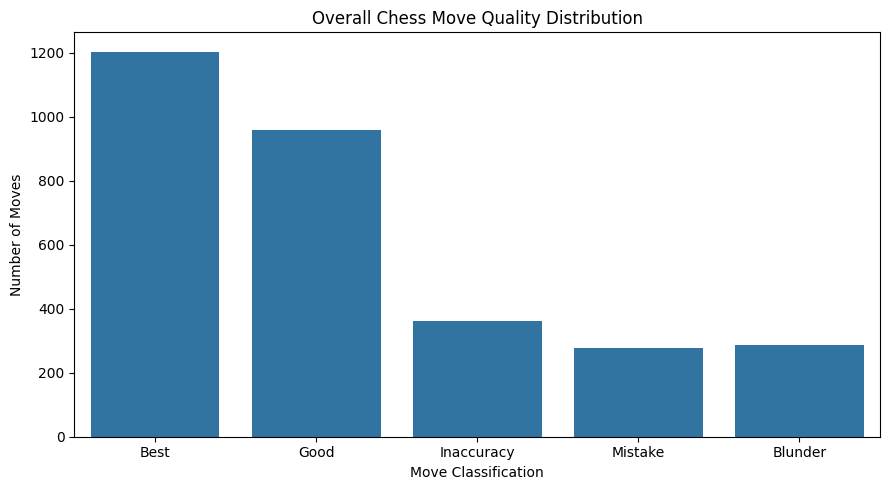

In [37]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="classification",
    order=["Best", "Good", "Inaccuracy", "Mistake", "Blunder"]
)

plt.title("Overall Chess Move Quality Distribution")
plt.xlabel("Move Classification")
plt.ylabel("Number of Moves")
plt.tight_layout()
plt.show()

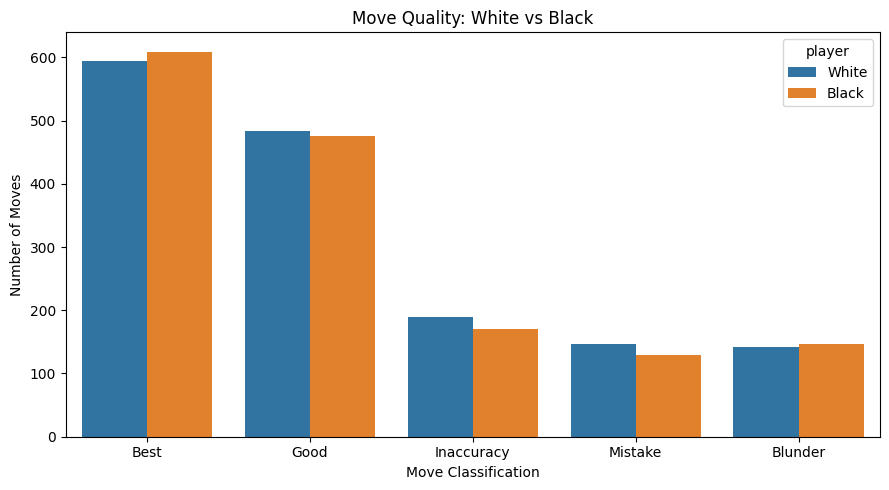

In [38]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="classification",
    hue="player",
    order=["Best", "Good", "Inaccuracy", "Mistake", "Blunder"]
)

plt.title("Move Quality: White vs Black")
plt.xlabel("Move Classification")
plt.ylabel("Number of Moves")
plt.tight_layout()
plt.show()

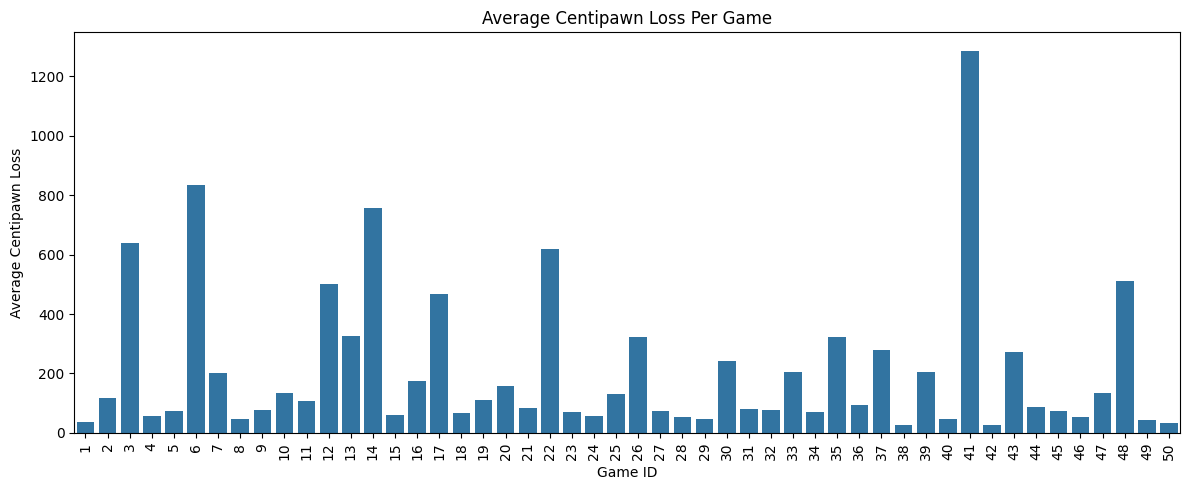

In [39]:
game_summary = df.groupby("game_id")[
    "centipawn_loss"
].mean().reset_index()

plt.figure(figsize=(12, 5))

sns.barplot(
    data=game_summary,
    x="game_id",
    y="centipawn_loss"
)

plt.title("Average Centipawn Loss Per Game")
plt.xlabel("Game ID")
plt.ylabel("Average Centipawn Loss")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [40]:
df.to_csv("chess_review_dataset.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [41]:
from google.colab import files

files.download("chess_review_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
player_summary.to_csv("player_performance_summary.csv")

files.download("player_performance_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check number of games
print("\nTotal games:", df["game_id"].nunique())

# Check move classification distribution
print("\nClassification distribution:")
print(df["classification"].value_counts())

# Check data types
print("\nColumn data types:")
print(df.dtypes)

Dataset shape: (3086, 12)

Missing values:
game_id           0
white             0
black             0
result            0
move_number       0
player            0
played_move       0
best_move         0
eval_before       0
eval_after        0
centipawn_loss    0
classification    0
dtype: int64

Total games: 50

Classification distribution:
classification
Best          1203
Good           958
Inaccuracy     360
Blunder        288
Mistake        277
Name: count, dtype: int64

Column data types:
game_id            int64
white             object
black             object
result            object
move_number        int64
player            object
played_move       object
best_move         object
eval_before        int64
eval_after         int64
centipawn_loss     int64
classification    object
dtype: object


In [44]:
# Create a copy of the dataset
ml_df = df.copy()

# Encode player
ml_df["player_encoded"] = ml_df["player"].map({
    "White": 0,
    "Black": 1
})

# Select input features
X = ml_df[
    [
        "move_number",
        "eval_before",
        "eval_after",
        "player_encoded"
    ]
]

# Select target variable
y = ml_df["classification"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features:


,move_number,eval_before,eval_after,player_encoded
0,1,40,36,0
1,1,-41,-68,1
2,2,64,47,0
3,2,-64,-78,1
4,3,71,76,0



Target:


,classification
0,Best
1,Good
2,Best
3,Good
4,Best



Feature shape: (3086, 4)
Target shape: (3086,)


In [45]:
from sklearn.model_selection import GroupShuffleSplit

# Split games, keeping all moves from each game together
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=ml_df["game_id"])
)

# Create training and testing datasets
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Check dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining games:",
      ml_df.iloc[train_idx]["game_id"].nunique())

print("Testing games:",
      ml_df.iloc[test_idx]["game_id"].nunique())

# Verify no game appears in both sets
train_games = set(ml_df.iloc[train_idx]["game_id"])
test_games = set(ml_df.iloc[test_idx]["game_id"])

print("\nOverlapping games:", train_games.intersection(test_games))

Training features: (2450, 4)
Testing features: (636, 4)

Training games: 40
Testing games: 10

Overlapping games: set()


In [46]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
dt_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [47]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict move classifications
y_pred = dt_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed performance report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["Best", "Good", "Inaccuracy", "Mistake", "Blunder"]
))

Model Accuracy: 47.17 %

Classification Report:
              precision    recall  f1-score   support

        Best       0.48      0.48      0.48       227
     Blunder       0.86      0.67      0.75        84
        Good       0.46      0.51      0.48       184
  Inaccuracy       0.50      0.16      0.24        76
     Mistake       0.25      0.45      0.32        65

    accuracy                           0.47       636
   macro avg       0.51      0.45      0.46       636
weighted avg       0.50      0.47      0.47       636


Confusion Matrix:
[[110  81   3  32   1]
 [ 67  93   4  19   1]
 [ 22  21  12  19   2]
 [ 17   9   5  29   5]
 [ 13   0   0  15  56]]


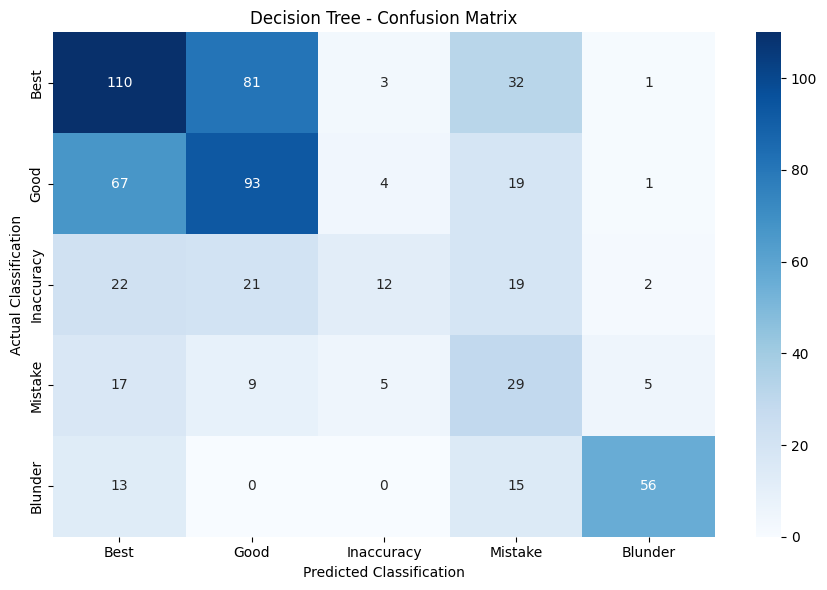

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = ["Best", "Good", "Inaccuracy", "Mistake", "Blunder"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Classification")
plt.ylabel("Actual Classification")
plt.tight_layout()
plt.show()

In [49]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [50]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions
rf_pred = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

# Detailed report
print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

Random Forest Accuracy: 63.99 %

Classification Report:
              precision    recall  f1-score   support

        Best       0.62      0.67      0.64       227
     Blunder       0.90      0.88      0.89        84
        Good       0.58      0.52      0.55       184
  Inaccuracy       0.49      0.59      0.54        76
     Mistake       0.76      0.65      0.70        65

    accuracy                           0.64       636
   macro avg       0.67      0.66      0.66       636
weighted avg       0.65      0.64      0.64       636



In [51]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ]
})

comparison["Accuracy (%)"] = (
    comparison["Accuracy"] * 100
)

display(comparison[["Model", "Accuracy (%)"]])

,Model,Accuracy (%)
0,Decision Tree,47.169811
1,Random Forest,63.993711


In [52]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report:\n")

print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

Random Forest Classification Report:

              precision    recall  f1-score   support

        Best       0.62      0.67      0.64       227
     Blunder       0.90      0.88      0.89        84
        Good       0.58      0.52      0.55       184
  Inaccuracy       0.49      0.59      0.54        76
     Mistake       0.76      0.65      0.70        65

    accuracy                           0.64       636
   macro avg       0.67      0.66      0.66       636
weighted avg       0.65      0.64      0.64       636



Feature Importance:


,Feature,Importance
2,eval_after,0.468210
1,eval_before,0.409076
0,move_number,0.106507
3,player_encoded,0.016207


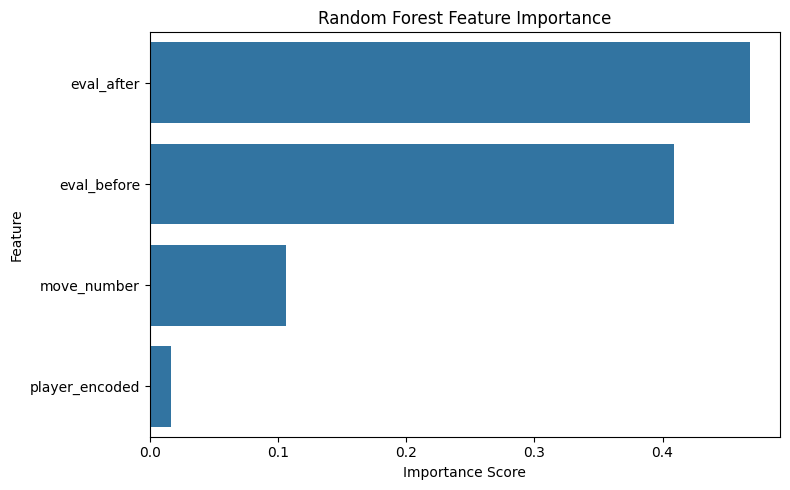

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(importance_df)

# Plot feature importance
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [54]:
import joblib

# Save trained model
joblib.dump(rf_model, "chess_review_model.pkl")

# Save feature names
joblib.dump(list(X_train.columns), "model_features.pkl")

print("Model and feature list saved successfully!")

Model and feature list saved successfully!


In [56]:
from google.colab import files

files.download("chess_review_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
import joblib

joblib.dump(rf_model, "chess_review_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [58]:
from google.colab import files

files.download("chess_review_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
import os

print("Model exists:", os.path.exists("chess_review_model.pkl"))
print("File size:", os.path.getsize("chess_review_model.pkl") if os.path.exists("chess_review_model.pkl") else "Not found")

Model exists: True
File size: 5275297


In [60]:
from google.colab import files

files.download("/content/chess_review_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [63]:
import os
import shutil

folder = "/content/drive/MyDrive/Chess_Review_Bot/models"
os.makedirs(folder, exist_ok=True)

shutil.copy2(
    "/content/chess_review_model.pkl",
    folder + "/chess_review_model.pkl"
)

print("Model copied successfully!")
print(os.listdir(folder))

Model copied successfully!
['chess_review_model.pkl']


In [64]:
import os
import joblib
import pandas as pd

os.makedirs("/content/submission/models", exist_ok=True)
os.makedirs("/content/submission/dataset", exist_ok=True)

# Export dataset
df.to_csv(
    "/content/submission/dataset/chess_dataset.csv",
    index=False
)

# Save both trained models
joblib.dump(
    dt_model,
    "/content/submission/models/decision_tree_model.pkl"
)

joblib.dump(
    rf_model,
    "/content/submission/models/random_forest_model.pkl"
)

# Save model feature names
joblib.dump(
    list(X_train.columns),
    "/content/submission/models/model_features.pkl"
)

print("All models and dataset saved successfully!")

All models and dataset saved successfully!


In [65]:
import shutil
import os

source = "/content/submission"
destination = "/content/drive/MyDrive/Chess_Review_Submission"

if os.path.exists(destination):
    shutil.rmtree(destination)

shutil.copytree(source, destination)

print("Copied successfully!")
print(os.listdir(destination))

Copied successfully!
['models', 'dataset']
